# Logistic Regression

**Goal:** predict whether a student **passes (1)** or **fails (0)** from hours studied, attendance and previous score.

**Why not linear regression?** Linear regression can output any number, even 1.7 or -0.4. For a yes/no answer we need a **probability between 0 and 1**. Logistic regression gets this by passing the linear score through the **sigmoid** function:

$$p = \frac{1}{1 + e^{-(b + w_1x_1 + w_2x_2 + w_3x_3)}}$$

If $p \ge 0.5$ we predict **pass**, otherwise **fail**.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load the data

In [2]:
df = pd.read_csv("student_results.csv")
df.head()

,hours_studied,attendance_pct,previous_score,passed
0,2.7,80.6,62.5,0
1,6.2,67.3,46.6,0
2,1.5,59.8,71.2,0
3,8.4,76.0,55.8,1
4,9.9,62.8,50.2,1


In [3]:
print("Pass rate:", round(df["passed"].mean(), 3))
df["passed"].value_counts()

Pass rate: 0.508


passed
1    2540
0    2460
Name: count, dtype: int64

A pass rate near 50% means the classes are balanced, so accuracy is a fair measure here.

## 3. Explore

In [4]:
df.groupby("passed").mean().round(1)

,hours_studied,attendance_pct,previous_score
passed,,,
0,3.5,72.1,55.6
1,6.4,77.1,63.7


Students who pass study more, attend more and have higher previous scores, so these inputs should help the model.

## 4. Split into training and test sets (70% / 30%)

In [5]:
features = ["hours_studied", "attendance_pct", "previous_score"]
X = df[features].to_numpy()
y = df["passed"].to_numpy().astype(int)

rng = np.random.default_rng(0)
idx = rng.permutation(len(y))
cut = int(0.7 * len(y))
train, test = idx[:cut], idx[cut:]

X_train, y_train = X[train], y[train]
X_test, y_test = X[test], y[test]
print("Training rows:", len(train), "  Test rows:", len(test))

Training rows: 3500   Test rows: 1500


## 5. Train the model with gradient descent

There is no one-step formula here, so we learn the weights gradually:

1. Start with all weights at 0.
2. Predict probabilities for the training data.
3. Measure the error: `p - y`.
4. Nudge the weights a small step (the learning rate) in the direction that reduces the **log loss**.
5. Repeat many times.

We first **scale** the inputs (subtract the mean, divide by the standard deviation) so that training converges quickly.

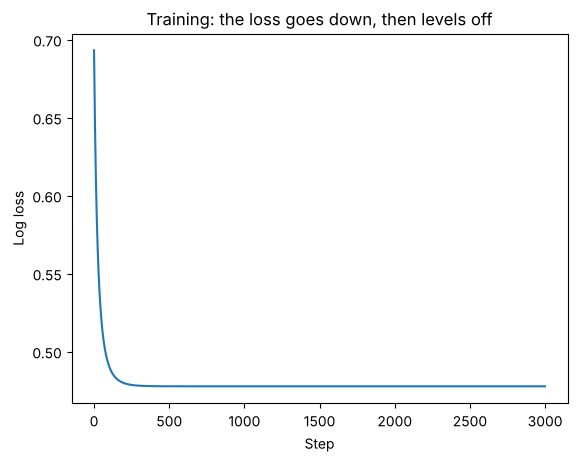

In [6]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

mu, sd = X_train.mean(axis=0), X_train.std(axis=0)
Z = (X_train - mu) / sd

w, b = np.zeros(Z.shape[1]), 0.0
lr = 0.1
losses = []

for step in range(3000):
    p = sigmoid(Z @ w + b)
    w -= lr * Z.T @ (p - y_train) / len(y_train)
    b -= lr * np.mean(p - y_train)
    p_safe = np.clip(p, 1e-12, 1 - 1e-12)
    losses.append(-np.mean(y_train * np.log(p_safe) + (1 - y_train) * np.log(1 - p_safe)))

# Convert the weights back to the original units
w_orig = w / sd
b_orig = b - np.sum(w * mu / sd)

plt.plot(losses)
plt.xlabel("Step")
plt.ylabel("Log loss")
plt.title("Training: the loss goes down, then levels off")
plt.show()

**Reading the weights.** The odds ratio `exp(w)` is how much one extra unit of that input multiplies the odds of passing.

In [7]:
for name, wi in zip(features, w_orig):
    print(f"{name:<15} weight = {wi:+.3f}   odds ratio = {np.exp(wi):.3f}")

hours_studied   weight = +0.510   odds ratio = 1.665
attendance_pct  weight = +0.039   odds ratio = 1.040
previous_score  weight = +0.060   odds ratio = 1.062


## 6. Predict on the test set

First we get probabilities, then turn them into 0 or 1 using a threshold of 0.5.

In [8]:
proba = sigmoid(X_test @ w_orig + b_orig)
pred = (proba >= 0.5).astype(int)
pd.DataFrame({"probability": proba[:8].round(3), "predicted": pred[:8], "actual": y_test[:8]})

,probability,predicted,actual
0,0.589,1,1
1,0.041,0,0
2,0.274,0,0
3,0.195,0,0
4,0.269,0,1
5,0.586,1,1
6,0.930,1,1
7,0.564,1,0


## 7. Evaluate: the confusion matrix

|  | Predicted fail (0) | Predicted pass (1) |
|---|---|---|
| **Actually failed (0)** | TN (correct) | FP (false alarm) |
| **Actually passed (1)** | FN (missed) | TP (correct) |

In [9]:
tn = int(np.sum((y_test == 0) & (pred == 0)))
fp = int(np.sum((y_test == 0) & (pred == 1)))
fn = int(np.sum((y_test == 1) & (pred == 0)))
tp = int(np.sum((y_test == 1) & (pred == 1)))

pd.DataFrame([[tn, fp], [fn, tp]],
             index=["Actual 0 (fail)", "Actual 1 (pass)"],
             columns=["Pred 0 (fail)", "Pred 1 (pass)"])

,Pred 0 (fail),Pred 1 (pass)
Actual 0 (fail),567,178
Actual 1 (pass),179,576


### Metrics

| Metric | Formula | Question it answers |
|---|---|---|
| **Accuracy** | (TP + TN) / total | How often is the model right overall? |
| **Precision** | TP / (TP + FP) | When it says "pass", how often is that true? |
| **Recall** | TP / (TP + FN) | Of the students who really passed, how many did it catch? |
| **Specificity** | TN / (TN + FP) | Of the students who really failed, how many did it catch? |
| **F1** | 2 × P × R / (P + R) | A single score balancing precision and recall |

In [10]:
accuracy = (tp + tn) / len(y_test)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
specificity = tn / (tn + fp)
f1 = 2 * precision * recall / (precision + recall)

print(f"Accuracy    = {accuracy:.3f}")
print(f"Precision   = {precision:.3f}")
print(f"Recall      = {recall:.3f}")
print(f"Specificity = {specificity:.3f}")
print(f"F1 score    = {f1:.3f}")

Accuracy    = 0.762
Precision   = 0.764
Recall      = 0.763
Specificity = 0.761
F1 score    = 0.763


## 8. Plots: confusion matrix and ROC curve

The **ROC curve** shows what happens as the threshold changes. The closer it hugs the top-left corner, the better. **AUC** is the area under it (0.5 = guessing, 1.0 = perfect).

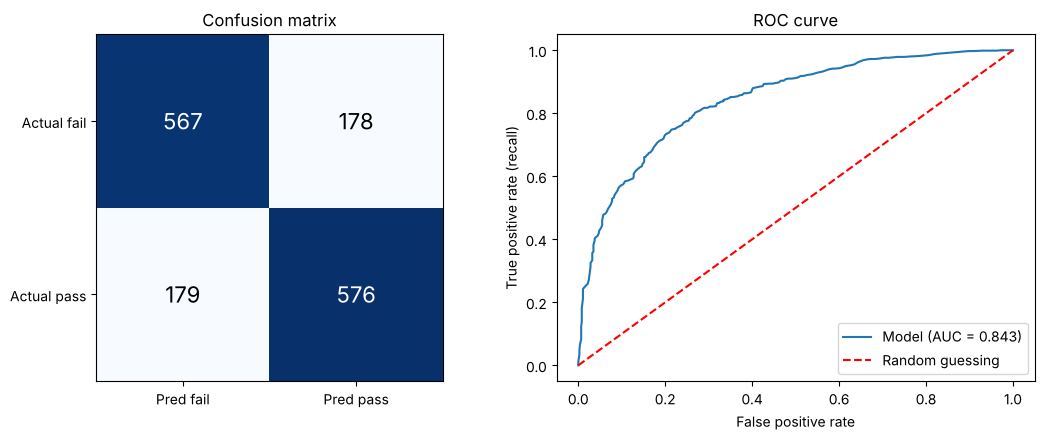

In [11]:
# ROC curve: try many thresholds
thresholds = np.linspace(1, 0, 201)
tpr = [np.sum((proba >= t) & (y_test == 1)) / np.sum(y_test == 1) for t in thresholds]
fpr = [np.sum((proba >= t) & (y_test == 0)) / np.sum(y_test == 0) for t in thresholds]
auc = np.trapezoid(tpr, fpr) if hasattr(np, "trapezoid") else np.trapz(tpr, fpr)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

cm = np.array([[tn, fp], [fn, tp]])
axes[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=16,
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
axes[0].set_xticks([0, 1], ["Pred fail", "Pred pass"])
axes[0].set_yticks([0, 1], ["Actual fail", "Actual pass"])
axes[0].set_title("Confusion matrix")

axes[1].plot(fpr, tpr, label=f"Model (AUC = {auc:.3f})")
axes[1].plot([0, 1], [0, 1], "r--", label="Random guessing")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate (recall)")
axes[1].set_title("ROC curve")
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Choosing a threshold

Lowering the threshold catches more passers (higher recall) but makes more false alarms (lower precision). Which is better depends on which mistake costs more.

In [12]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pr = (proba >= t).astype(int)
    TP = np.sum((pr == 1) & (y_test == 1)); FP = np.sum((pr == 1) & (y_test == 0))
    FN = np.sum((pr == 0) & (y_test == 1))
    P, R = TP / (TP + FP), TP / (TP + FN)
    rows.append([t, P, R, 2 * P * R / (P + R), np.mean(pr == y_test)])

pd.DataFrame(rows, columns=["threshold", "precision", "recall", "F1", "accuracy"]).round(3)

,threshold,precision,recall,F1,accuracy
0,0.3,0.679,0.886,0.769,0.732
1,0.4,0.725,0.832,0.775,0.757
2,0.5,0.764,0.763,0.763,0.762
3,0.6,0.806,0.675,0.735,0.755
4,0.7,0.847,0.580,0.689,0.736


## 10. Conclusion

- The model is right about **76%** of the time, with precision, recall and F1 all near 0.76 and an AUC of about 0.84, which is a good but not perfect classifier.
- **Hours studied** has the strongest effect: each extra hour multiplies the odds of passing by about 1.67.
- The threshold is a choice: raising it gives fewer false alarms, lowering it misses fewer real passers.